# Exploring slices, intervals and signed contributions

A finite encoding lets us ask several questions of the same spaces and maps. A
slice follows one chain. A rank measure reorganizes all comparable-pair ranks.
A Hilbert measure records dimensions. Here we explore what their pictures mean,
including why a negative coefficient can be necessary for a positive answer.

You need Julia, TamerOp and CairoMakie, and familiarity with the
[spaces and maps of a finite encoding](../spaces_and_maps.md). We will start from
a supplied finite diagram; no point cloud or filtration construction is needed.
The workflow is: build the encoding, inspect a slice, then reconstruct selected
queries from signed terms. Live controls and exporting are optional continuations.


In [1]:
using TamerOp, CairoMakie
const A = TamerOp.Advanced
const F = TamerOp.FiniteFringe
const E = TamerOp.EncodingCore
const Mds = TamerOp.Modules
const S = TamerOp.SignedMeasures


TamerOp.SignedMeasures

## One module, several questions

Use the grid with coordinates 0, 2 and 5 on each axis. Put a one-dimensional
space at every vertex except the upper-right vertex, where the space is zero.
Every map between nonzero spaces is the identity. Thus the support is the union
of two overlapping strips. The missing corner makes the diagonal class die.

The classifier uses the greatest grid coordinate below a parameter: spaces are
constant between consecutive coordinates, zero below the grid, and constant
past the final coordinate. That convention determines the half-open endpoints
and infinite tails in the figures below. Constructing the module explicitly is
appropriate here because its nine spaces and maps are the mathematical input.


In [2]:
coordinates = [0, 2, 5]
P = F.ProductOfChainsPoset((3, 3))
classifier = E.GridEncodingMap(P, (coordinates, coordinates))
field = TamerOp.CoreModules.QQField()
K = Rational{BigInt}
stalk_dimensions = [x <= 2 || y <= 2 ? 1 : 0 for y in coordinates for x in coordinates]
maps = Dict((a,b) => fill(one(K), stalk_dimensions[b], stalk_dimensions[a])
            for (a,b) in F.cover_edges(P))
module_ = Mds.PModule{K}(P, stalk_dimensions, maps; field)
encoding = TamerOp.Results.EncodingResult(P, module_, classifier)
TamerOp.describe(encoding)


(kind = :encoding_result, poset_type = TamerOp.FiniteFringe.ProductOfChainsPoset{2}, module_type = TamerOp.Modules.PModule{Rational{BigInt}, TamerOp.CoreModules.CoeffFields.QQField, Matrix{Rational{BigInt}}, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, encoding_map_type = TamerOp.EncodingCore.GridEncodingMap{2, Int64, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, compiled = false, backend = :auto, has_cohomology = false, has_presentation = false, module_dims = [1, 1, 1, 1, 1, 1, 1, 1, 0], materialized = true, provenance = (category = :finite_poset_representations, base_poset = ProductOfChainsPoset(axes=(3, 3), nvertices=9), field = TamerOp.CoreModules.CoeffFields.QQField(), degree = nothing, degree_convention = :not_applicable, encoding = (map_type = TamerOp.EncodingCore.GridEncodingMap{2, Int64, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, backend = :auto), window = :not_recorded, orientation = :not_recorded, construction = (requested = :not_recorded, effective = :not_recorded, s

Restrict first to the diagonal chain of labels 1, 5 and 9, at parameter values
0, 2 and 5. There is one interval born at 0 and dying at 5. This is an explicit
chain restriction, with all changes along this diagonal included.


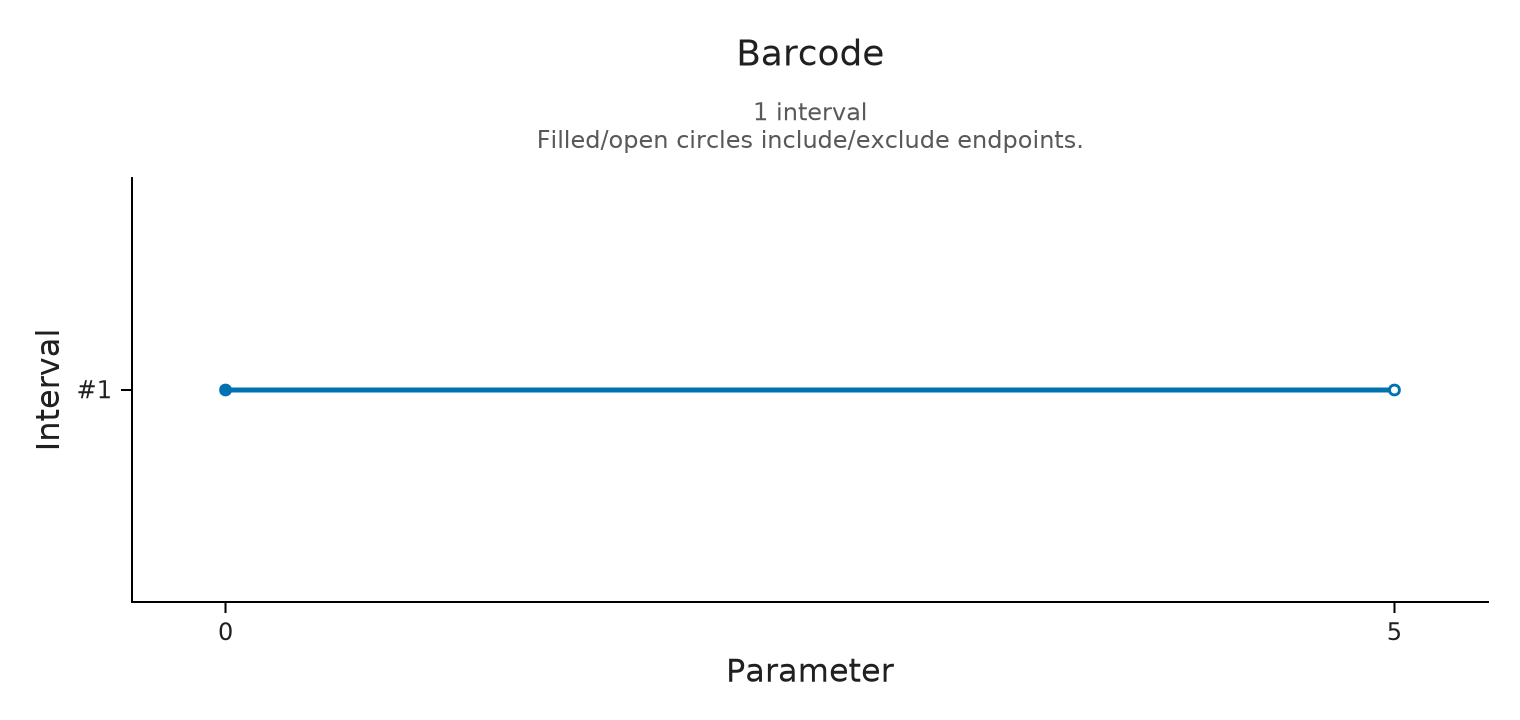

In [3]:
diagonal = slice_barcode(module_, [1, 5, 9]; values=[0, 2, 5])
@assert diagonal == Dict((0, 5) => 1)
visualize(diagonal; kind=:barcode)


## Why the rank description needs a negative term

`rank_signed_measure` returns endpoint pairs with integer coefficients. Each
four-coordinate atom keeps both a two-dimensional birth and a two-dimensional
death. Its half-open rectangle contributes to the rank from **p** to **q** exactly
when it contains both points. It is not a structure-map arrow.

Ask for the rank from (0,0) to (2,2), in the overlap. Both strips contribute +1;
the overlap contributes −1 to correct the double count. The result is 1. The
prominence panel puts positive side lengths in the positive quadrant and
negative side lengths in the negative quadrant; labels retain term IDs and
multiplicity. Infinite sides have labelled display positions, not finite deaths.


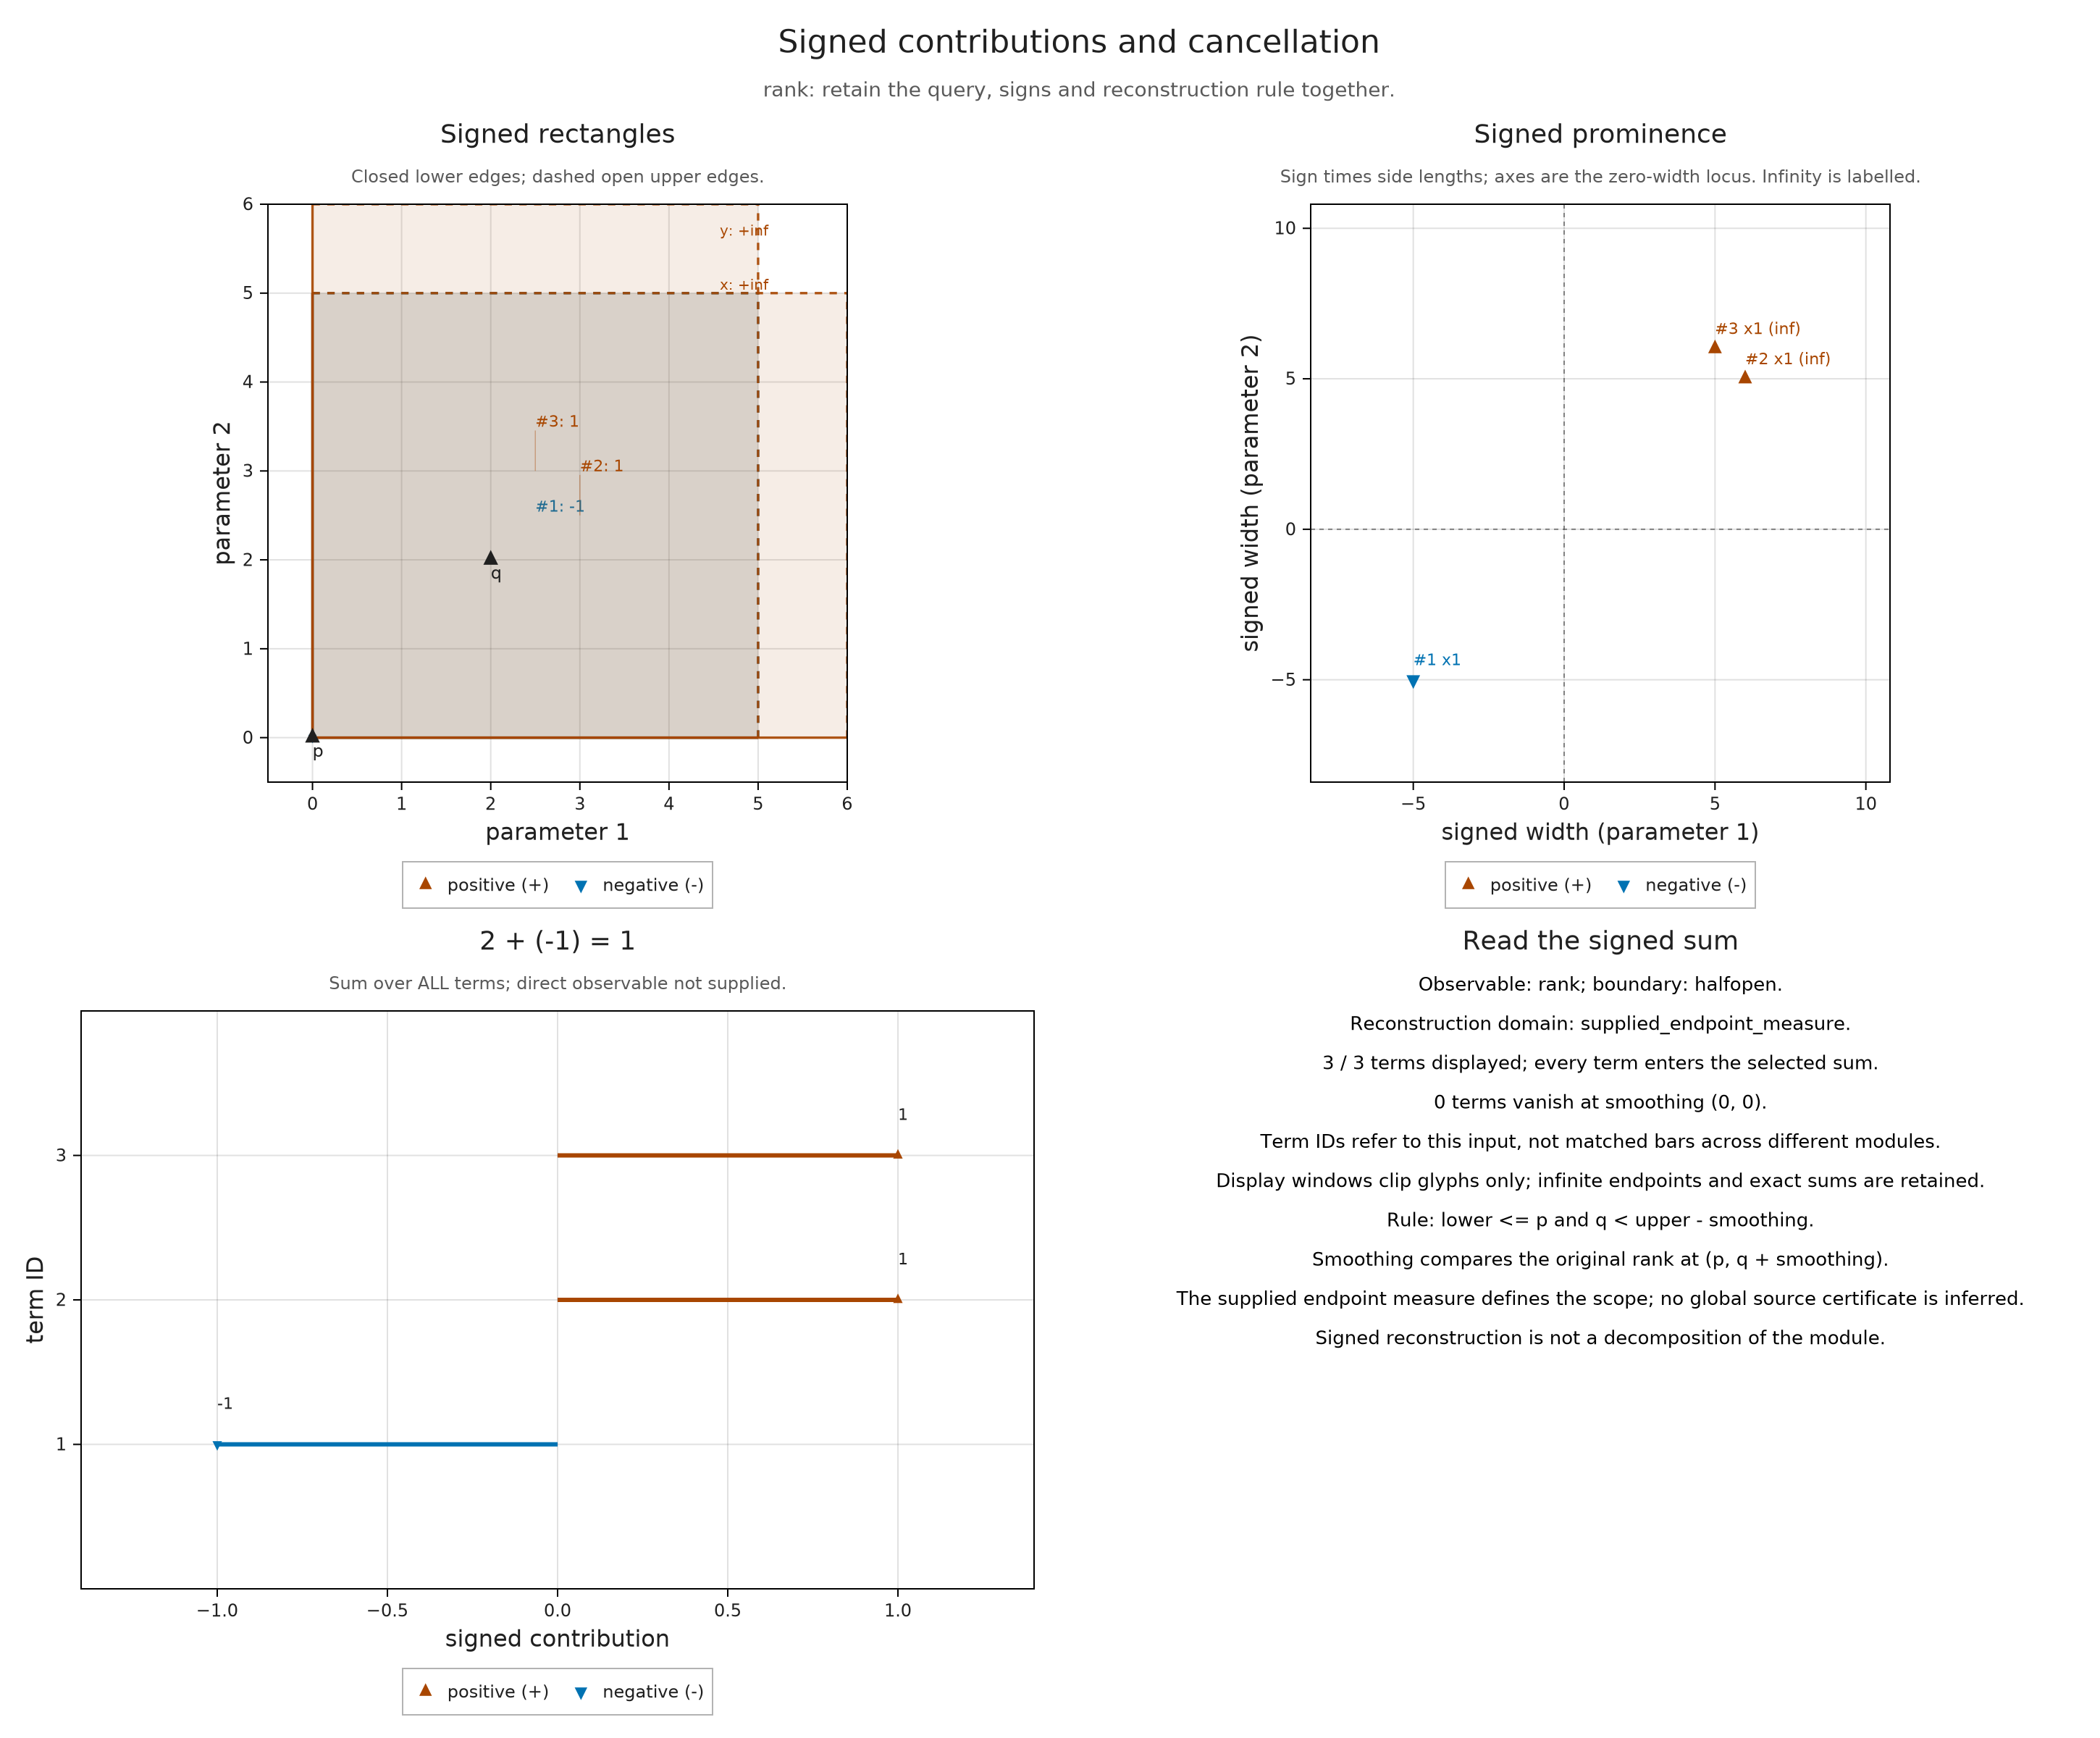

In [4]:
rank_measure = rank_signed_measure(encoding; threads=false)
visualize(rank_measure; query=(p=(0,0), q=(2,2)))


The sum alone checks the measure's arithmetic. To compare it with the original
module, supply a direct rank query. Here that query locates the two finite labels
and asks the algebra owner for the rank of their actual map. It never reads the
signed coefficients. Selecting a term links its geometry, width and contribution.


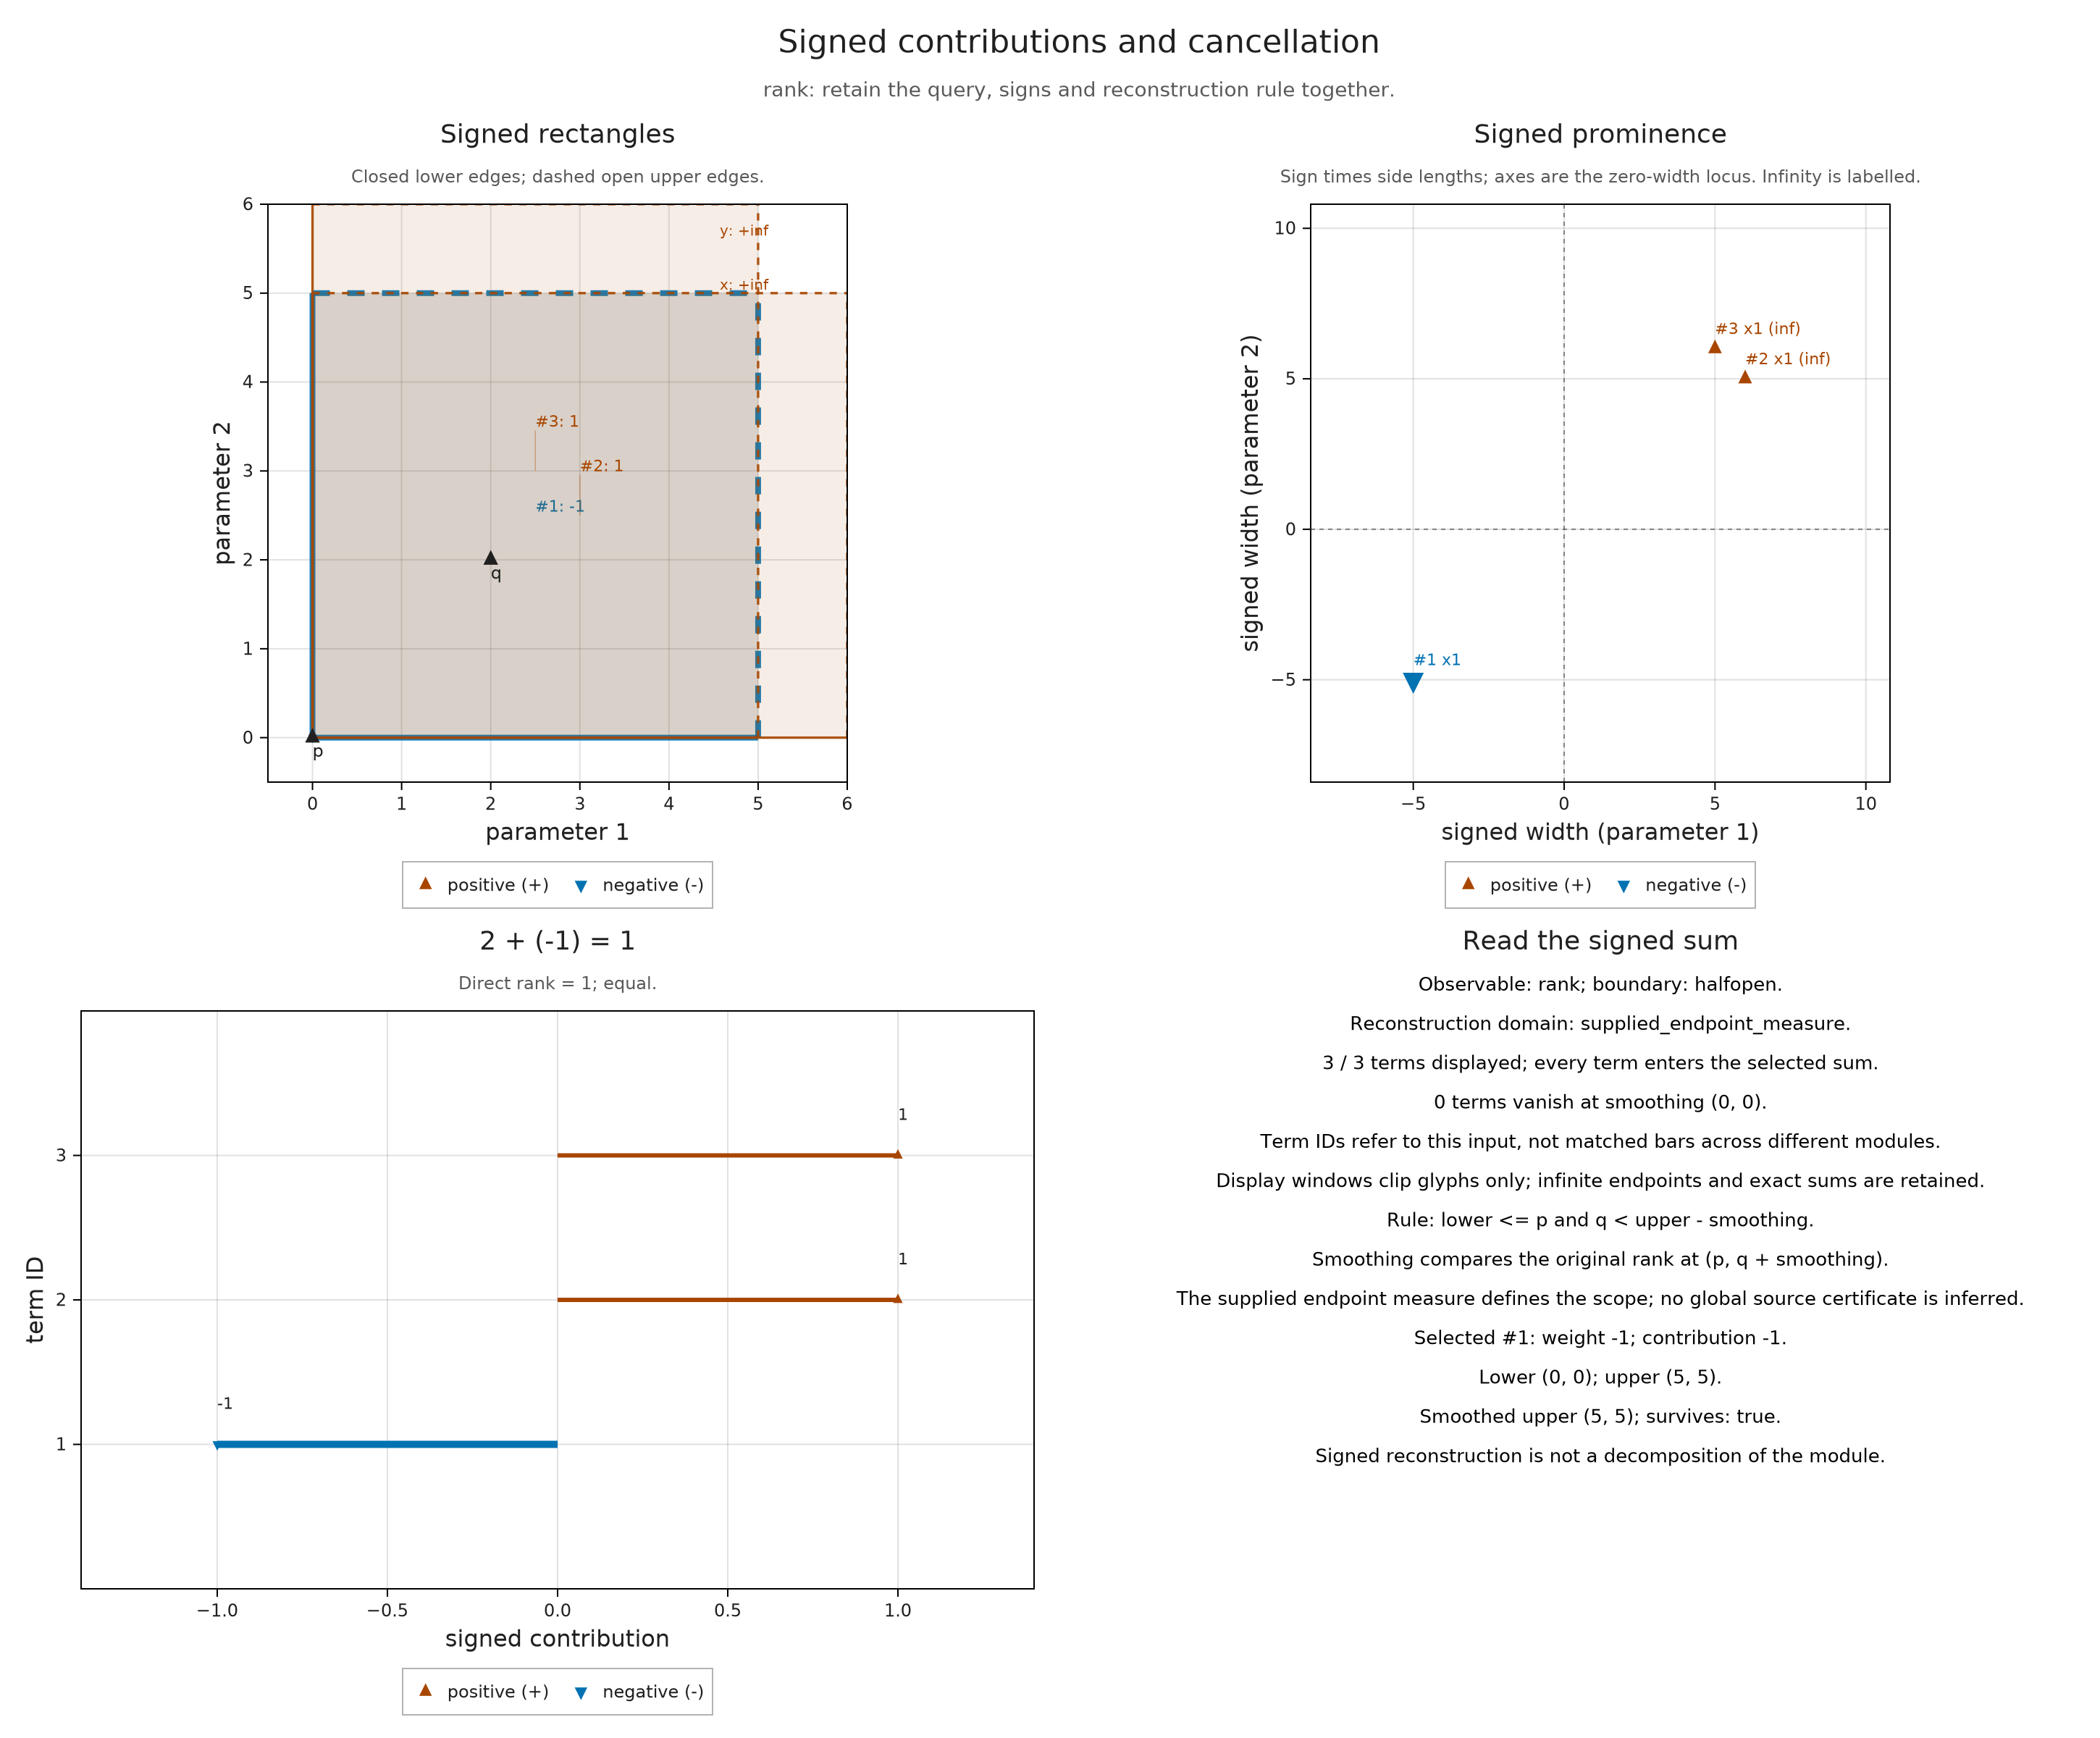

In [5]:
direct_rank = (p,q) -> TamerOp.Invariants.rank_map(module_,
    E.locate(classifier, collect(p)), E.locate(classifier, collect(q)))
negative_term = findfirst(<(0), S.weights(rank_measure))
signed_view = A.visual_spec(rank_measure; query=(p=(0,0), q=(2,2)),
    direct=direct_rank, term=negative_term)
@assert signed_view.metadata.agreement == :equal
@assert signed_view.metadata.reconstructed == 1
visualize(signed_view)


Diagonals offer a less filled-in view of the same endpoint pairs. The optional
display window clips the drawing only. It does not cap the infinite endpoints or
change the sum. Positive and negative terms use different marker shapes as well
as colors, so the signs remain available in grayscale.


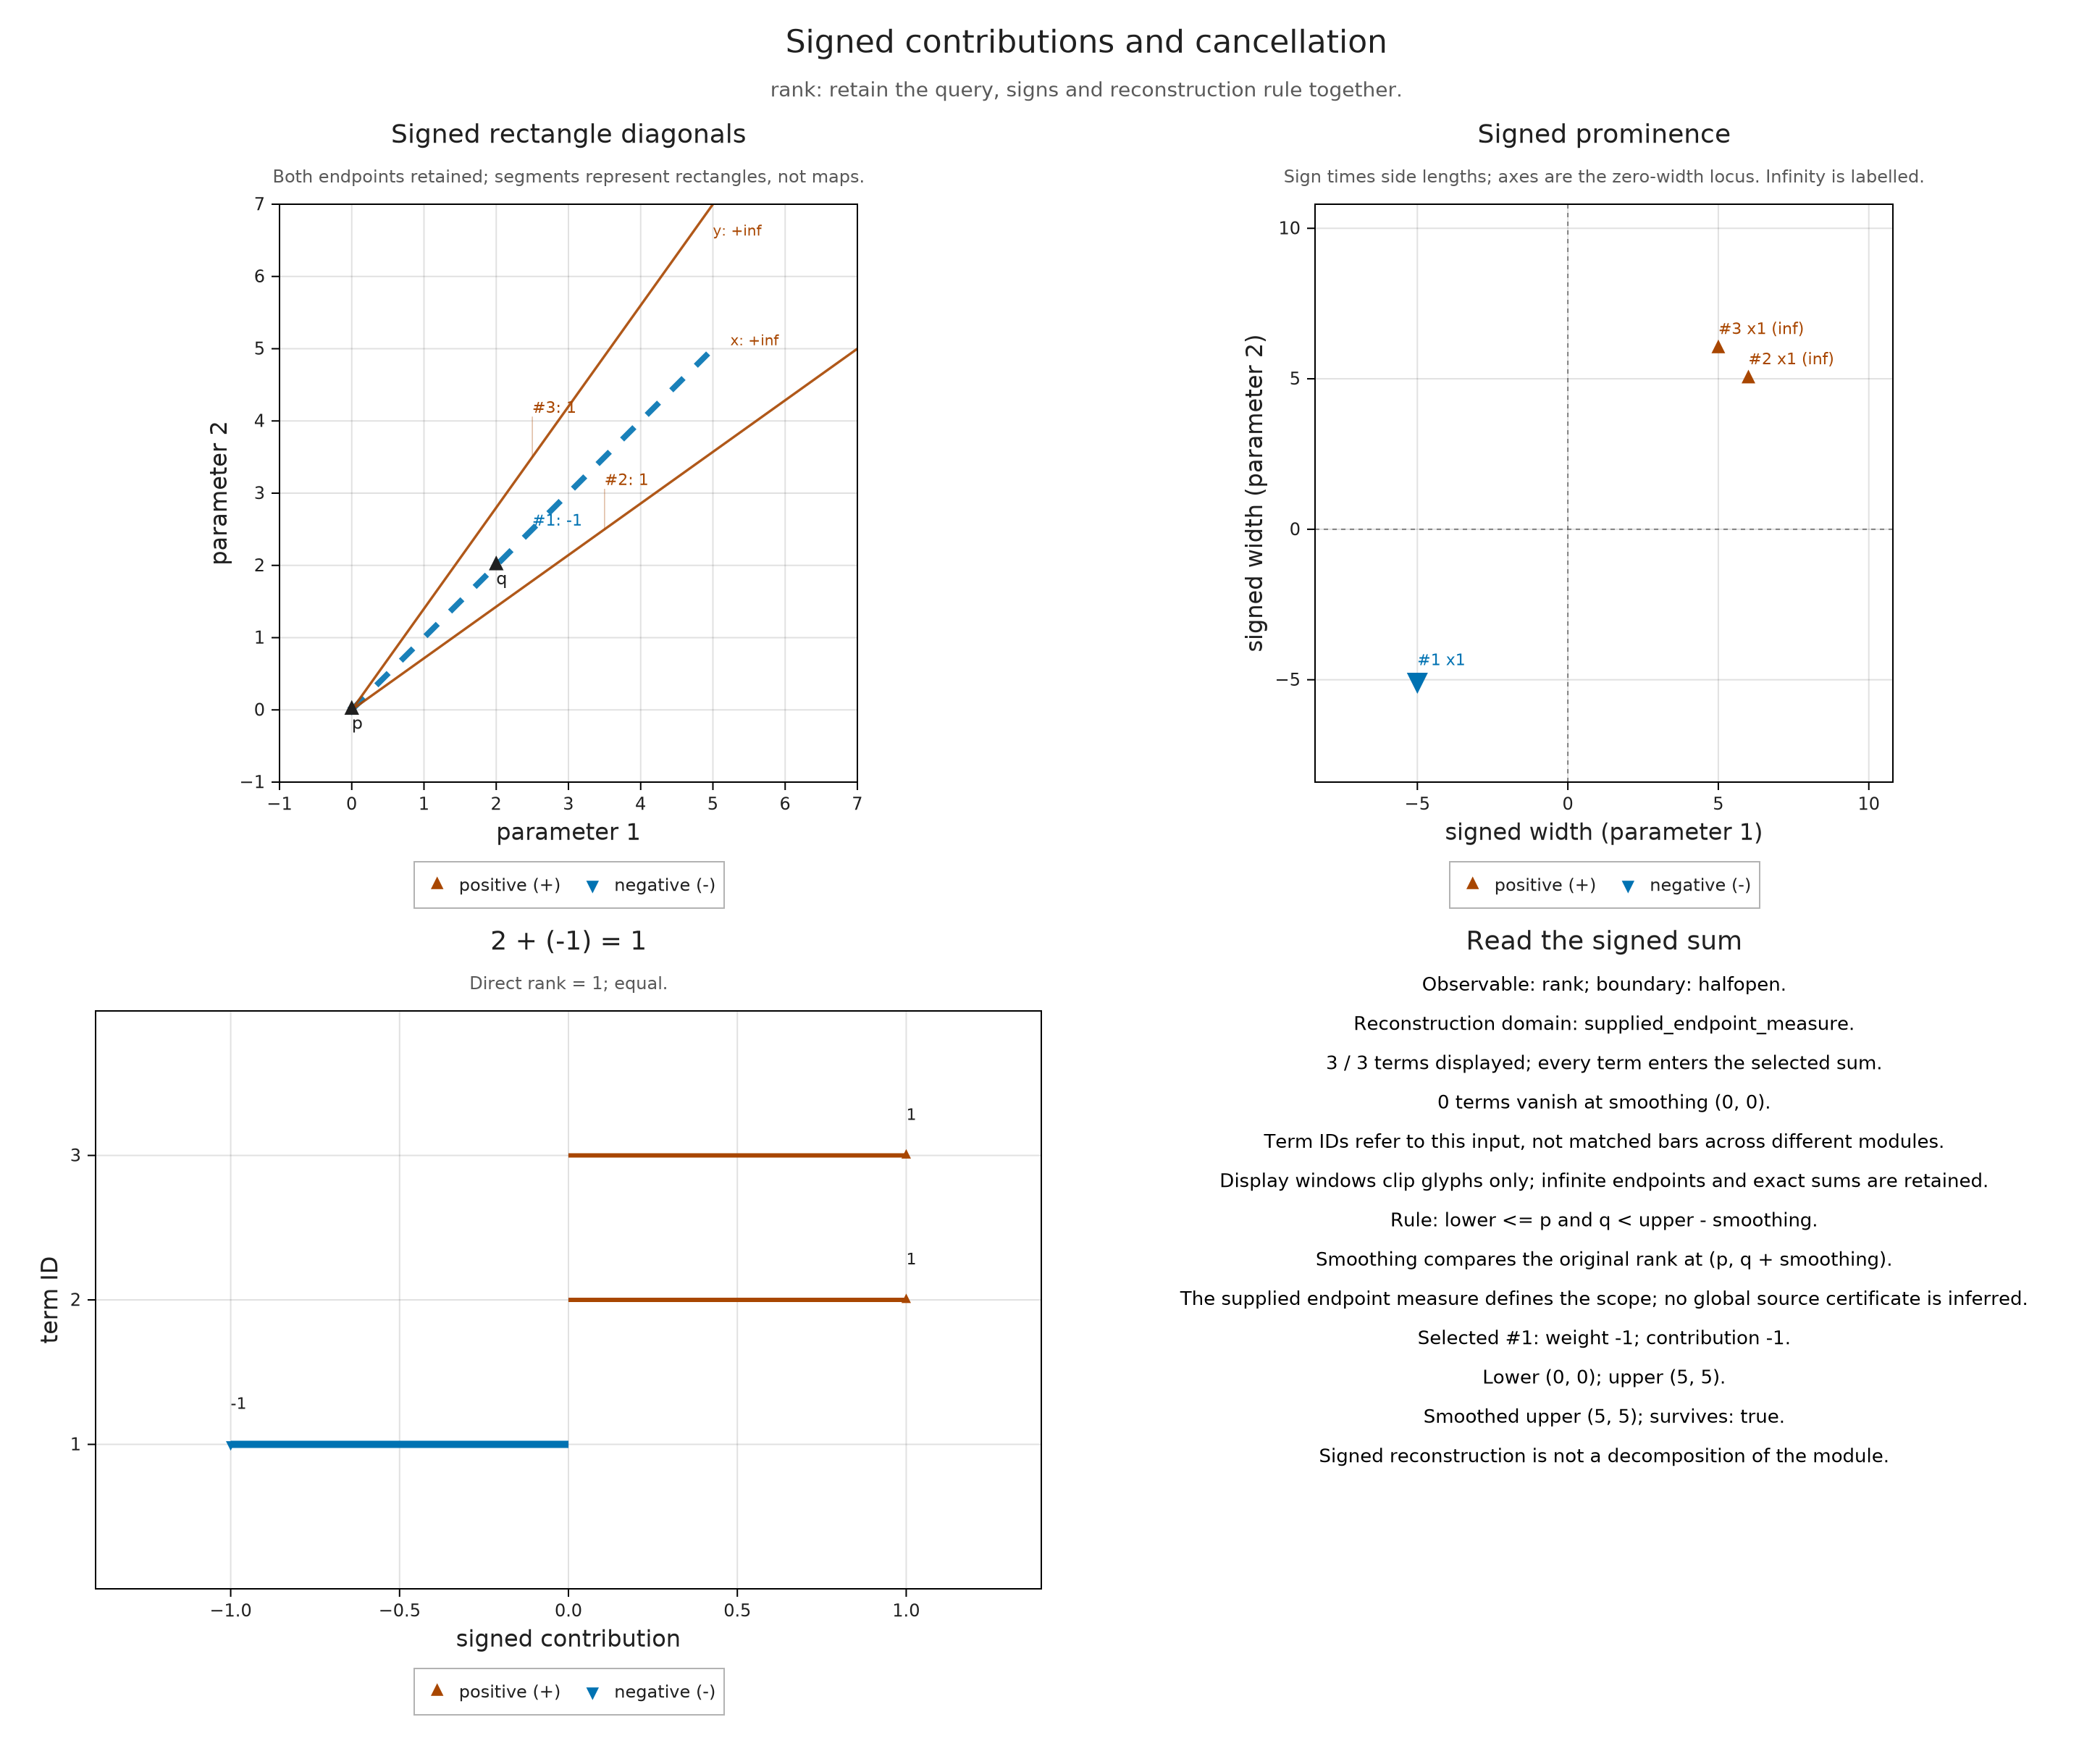

In [6]:
visualize(rank_measure; kind=:signed_diagonals, query=(p=(0,0), q=(2,2)),
    direct=direct_rank, term=negative_term, window=((-1,-1),(7,7)))


## Smoothing has a precise meaning

For a nonnegative vector ε, smoothing takes the image of the map from the module
to its ε-shift. Its rank from p to q is the original rank from p to q+ε.
On each rectangle this shifts the upper endpoint by −ε and removes empty
rectangles. This is the smoothing of
[Botnan, Oppermann and Oudot, §6.2](https://link.springer.com/article/10.1007/s10208-024-09672-9).
It is different from convolving a plotted density with a kernel.

At ε=(3,3), our query now tests the original map to (5,5), whose target is zero.
The arithmetic changes to zero. The strict upper-endpoint convention matters:
a query on an excluded upper edge contributes nothing.


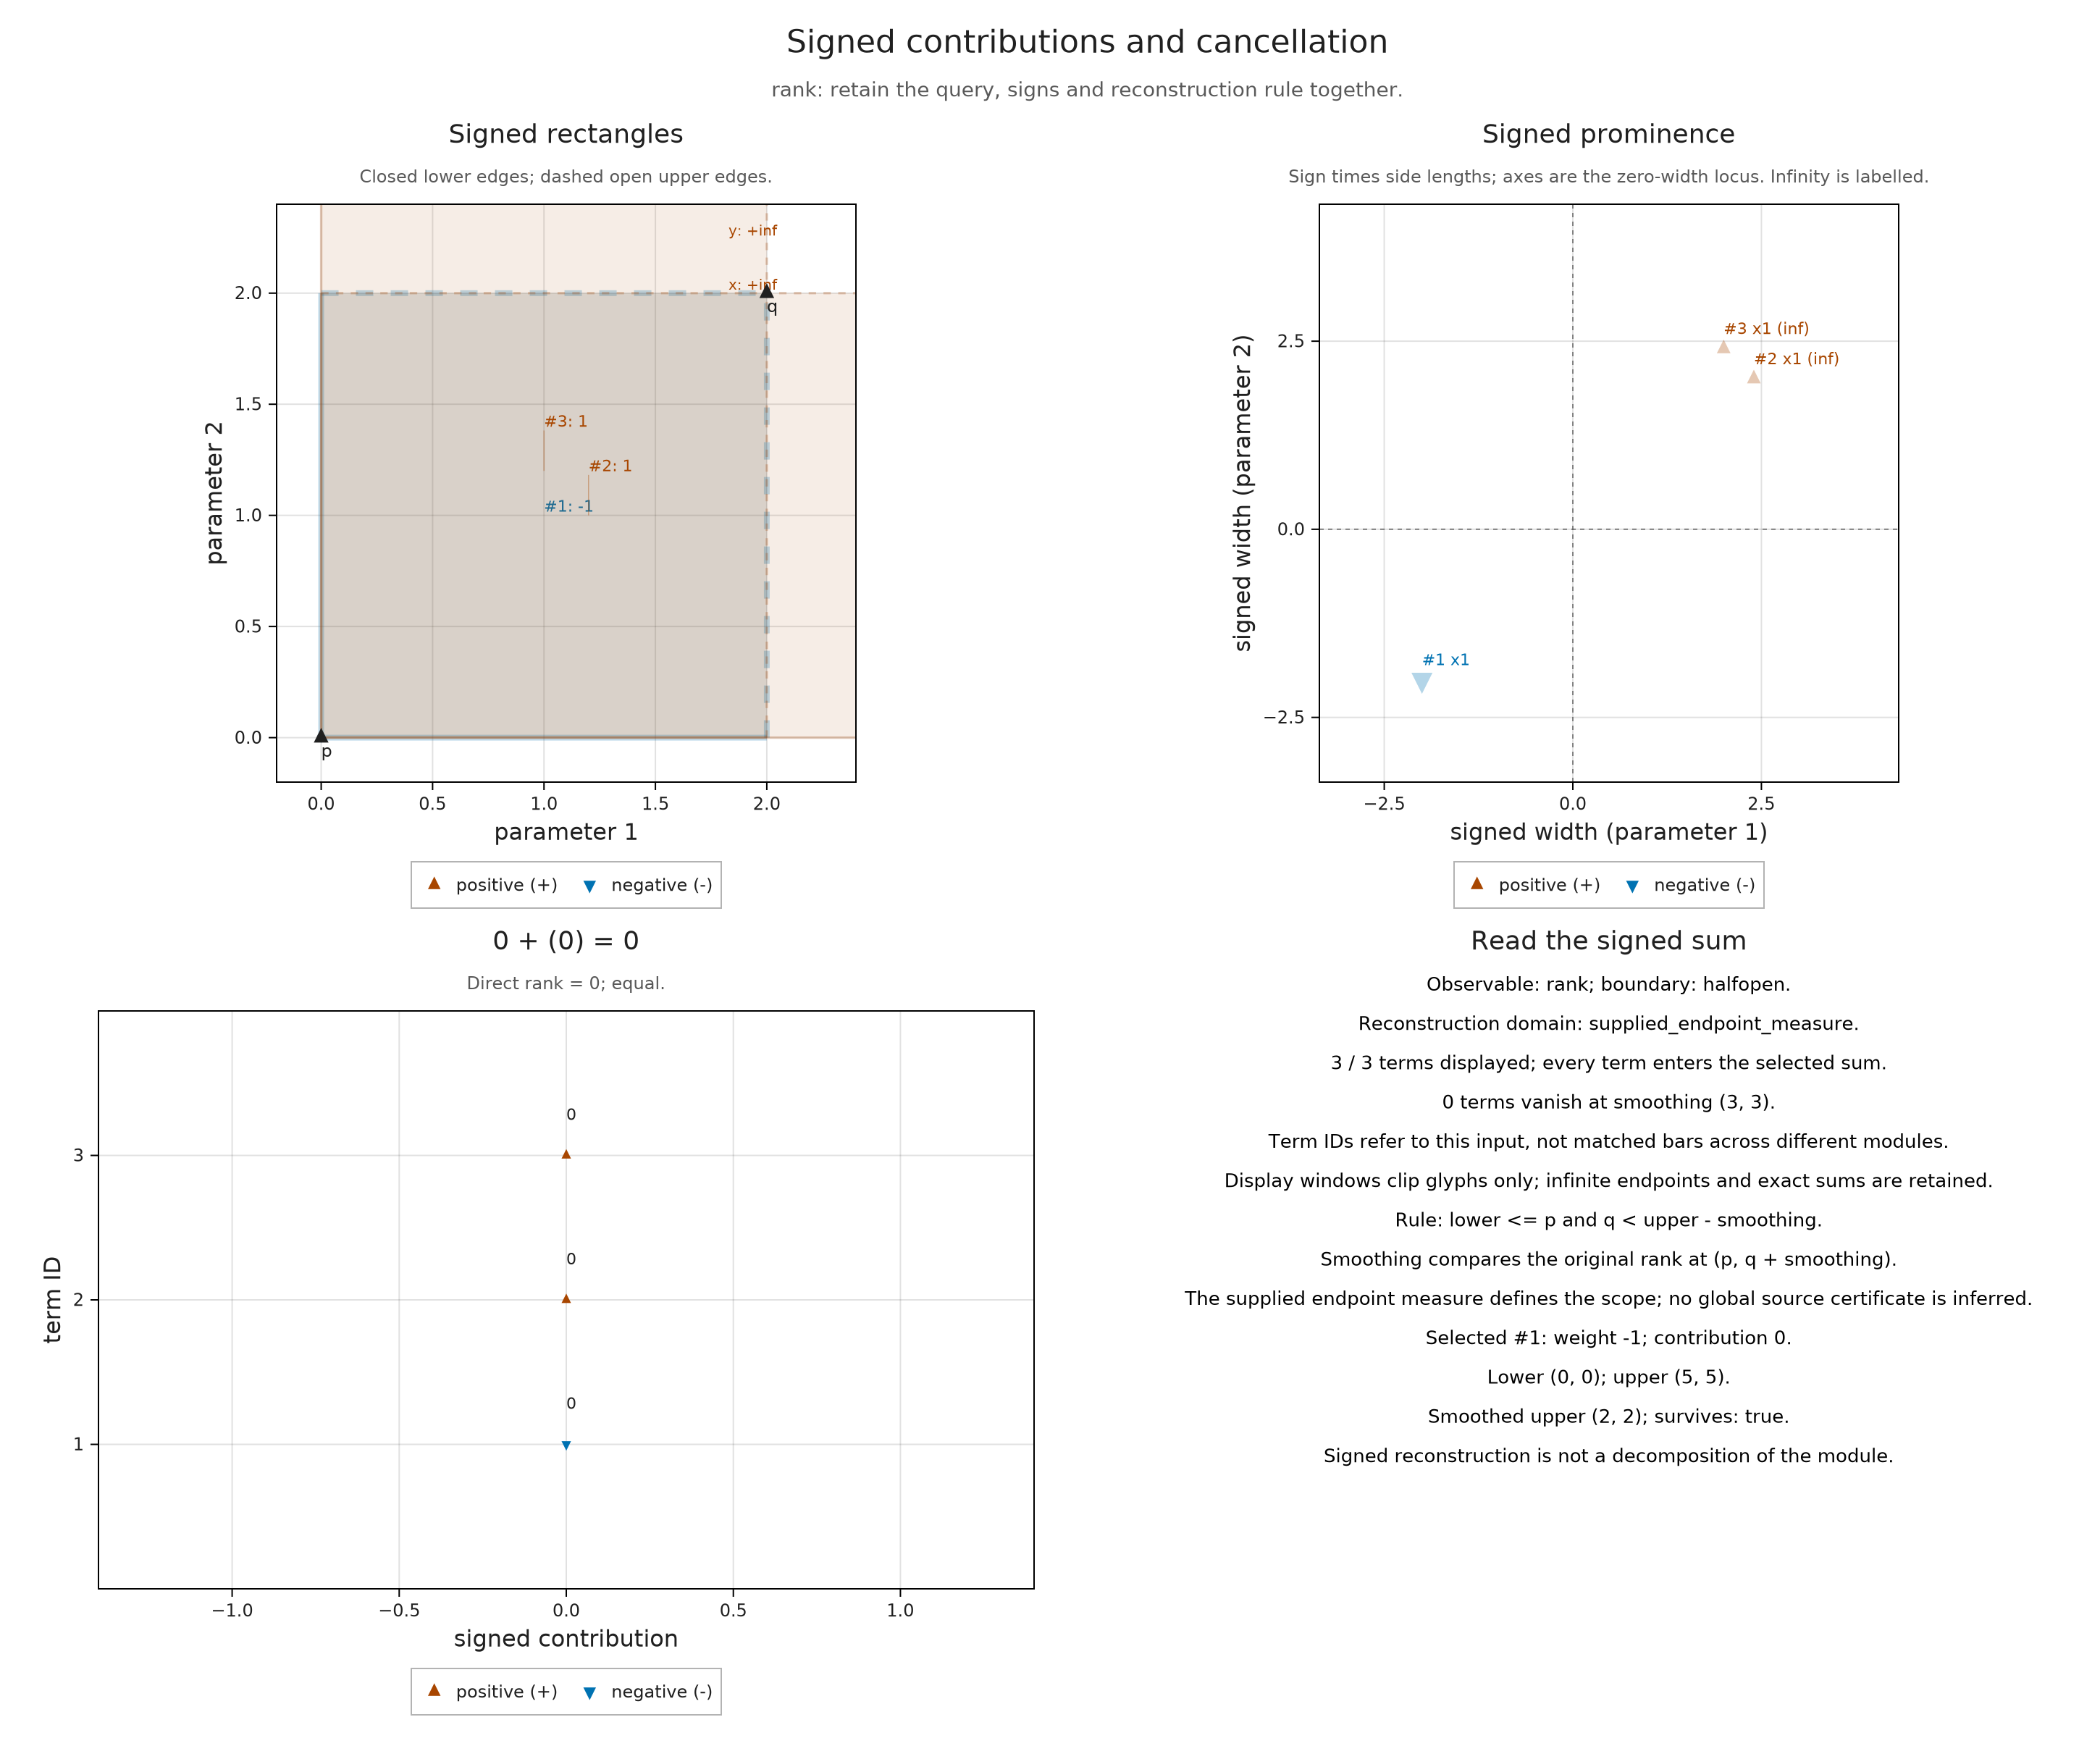

In [7]:
smoothed_view = A.visual_spec(rank_measure; query=(p=(0,0), q=(2,2)),
    smoothing=(3,3), direct=direct_rank, term=negative_term)
@assert smoothed_view.metadata.agreement == :equal
@assert smoothed_view.metadata.reconstructed == 0
visualize(smoothed_view)


## Dimensions use a different signed sum

For a Hilbert function, a point atom contributes when it lies below the query
coordinatewise. There is no second endpoint. At (5,5), the birth atom contributes
+1 and the correction contributes −1, giving dimension zero.

The optional background below is explicitly identified as the same module's
Hilbert samples. Colored sample points avoid assuming interpolation between grid coordinates. Its matrix uses rows for y and columns for x. The axes and units
must agree with those of the atoms; an arbitrary image would not establish that
correspondence. This background is a sampled dimension view, not a convolution.


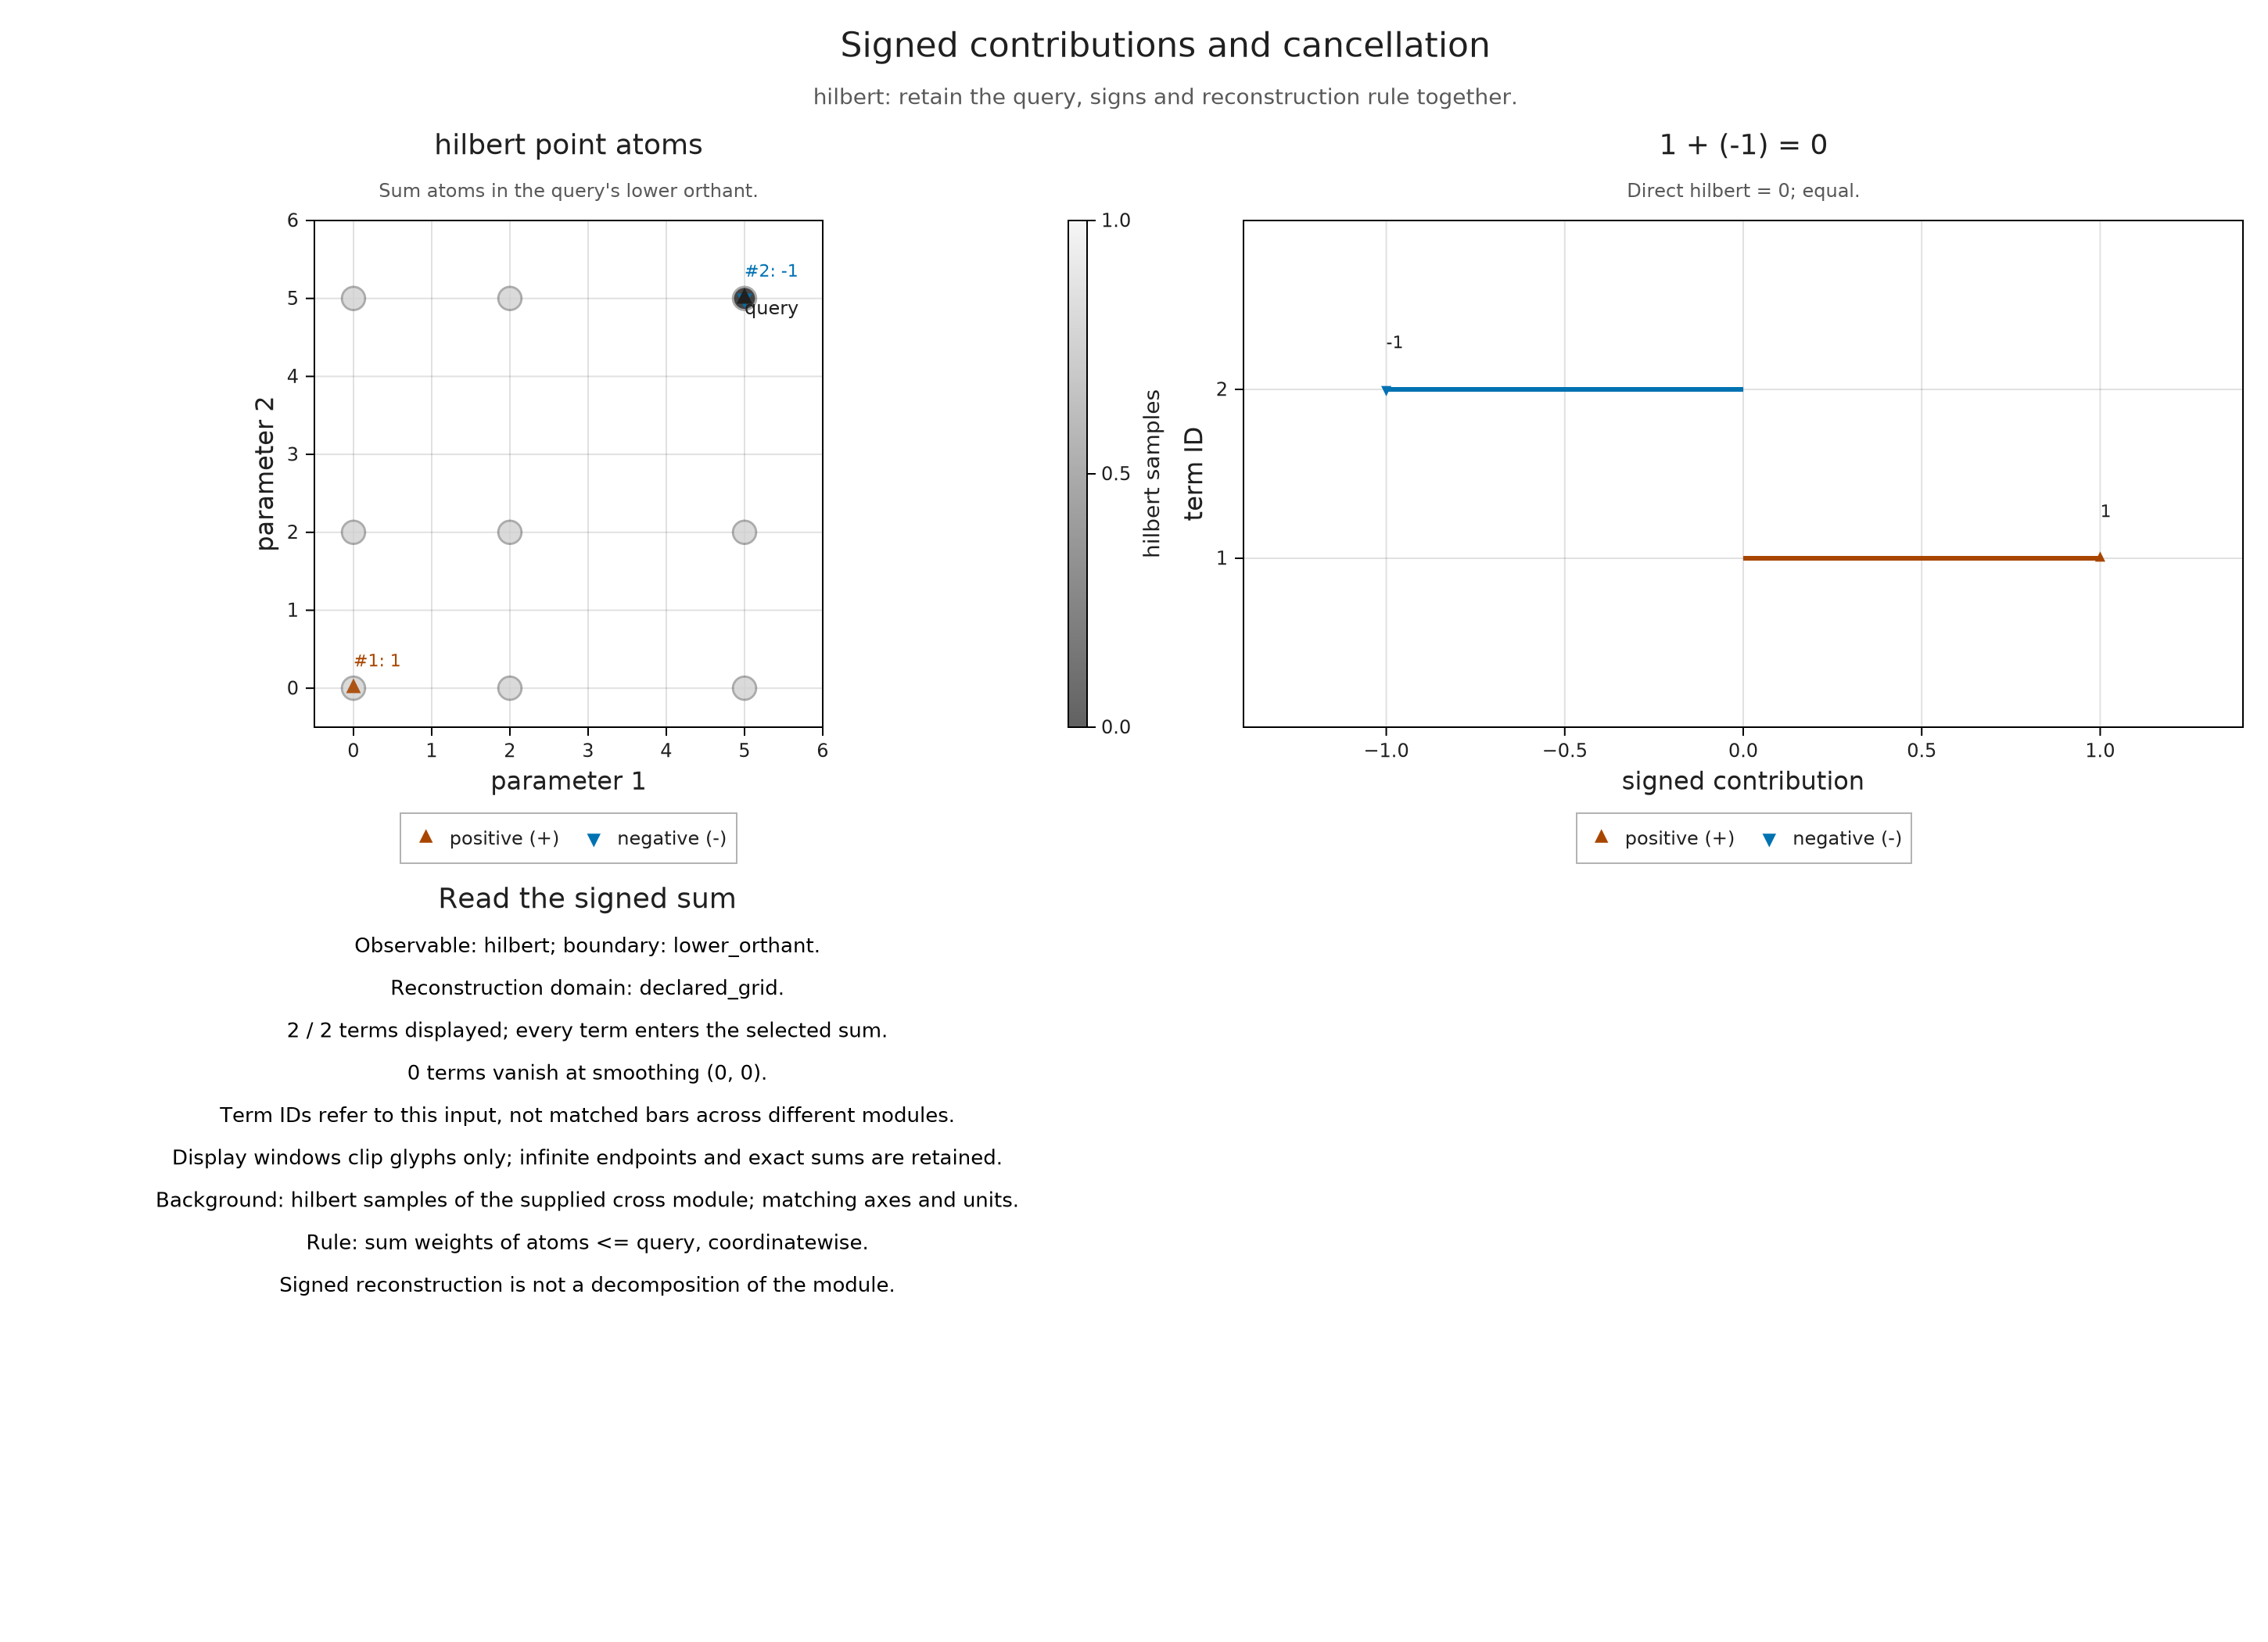

In [8]:
hilbert = [restricted_hilbert(module_, classifier, [x,y]) for x in coordinates, y in coordinates]
atoms = S.point_signed_measure(hilbert, (coordinates, coordinates))
background = (axes=(coordinates, coordinates), values=permutedims(hilbert),
    observable=:hilbert, source="the supplied cross module", units=("parameter 1", "parameter 2"))
visualize(atoms; kind=:signed_cancellation, observable=:hilbert, query=(5,5),
    direct=p -> restricted_hilbert(module_, classifier, collect(p)), background)


## A declared family of finite regions

The same module also supports generalized-rank queries on connected, convex
sets of finite labels. Declare the horizontal strip, vertical strip and their
overlap. The summary is certified on those declared queries. This is a different
domain from the comparable-pair rank measure, even when the small example gives
similar arithmetic. The table displays membership in the actual finite regions.


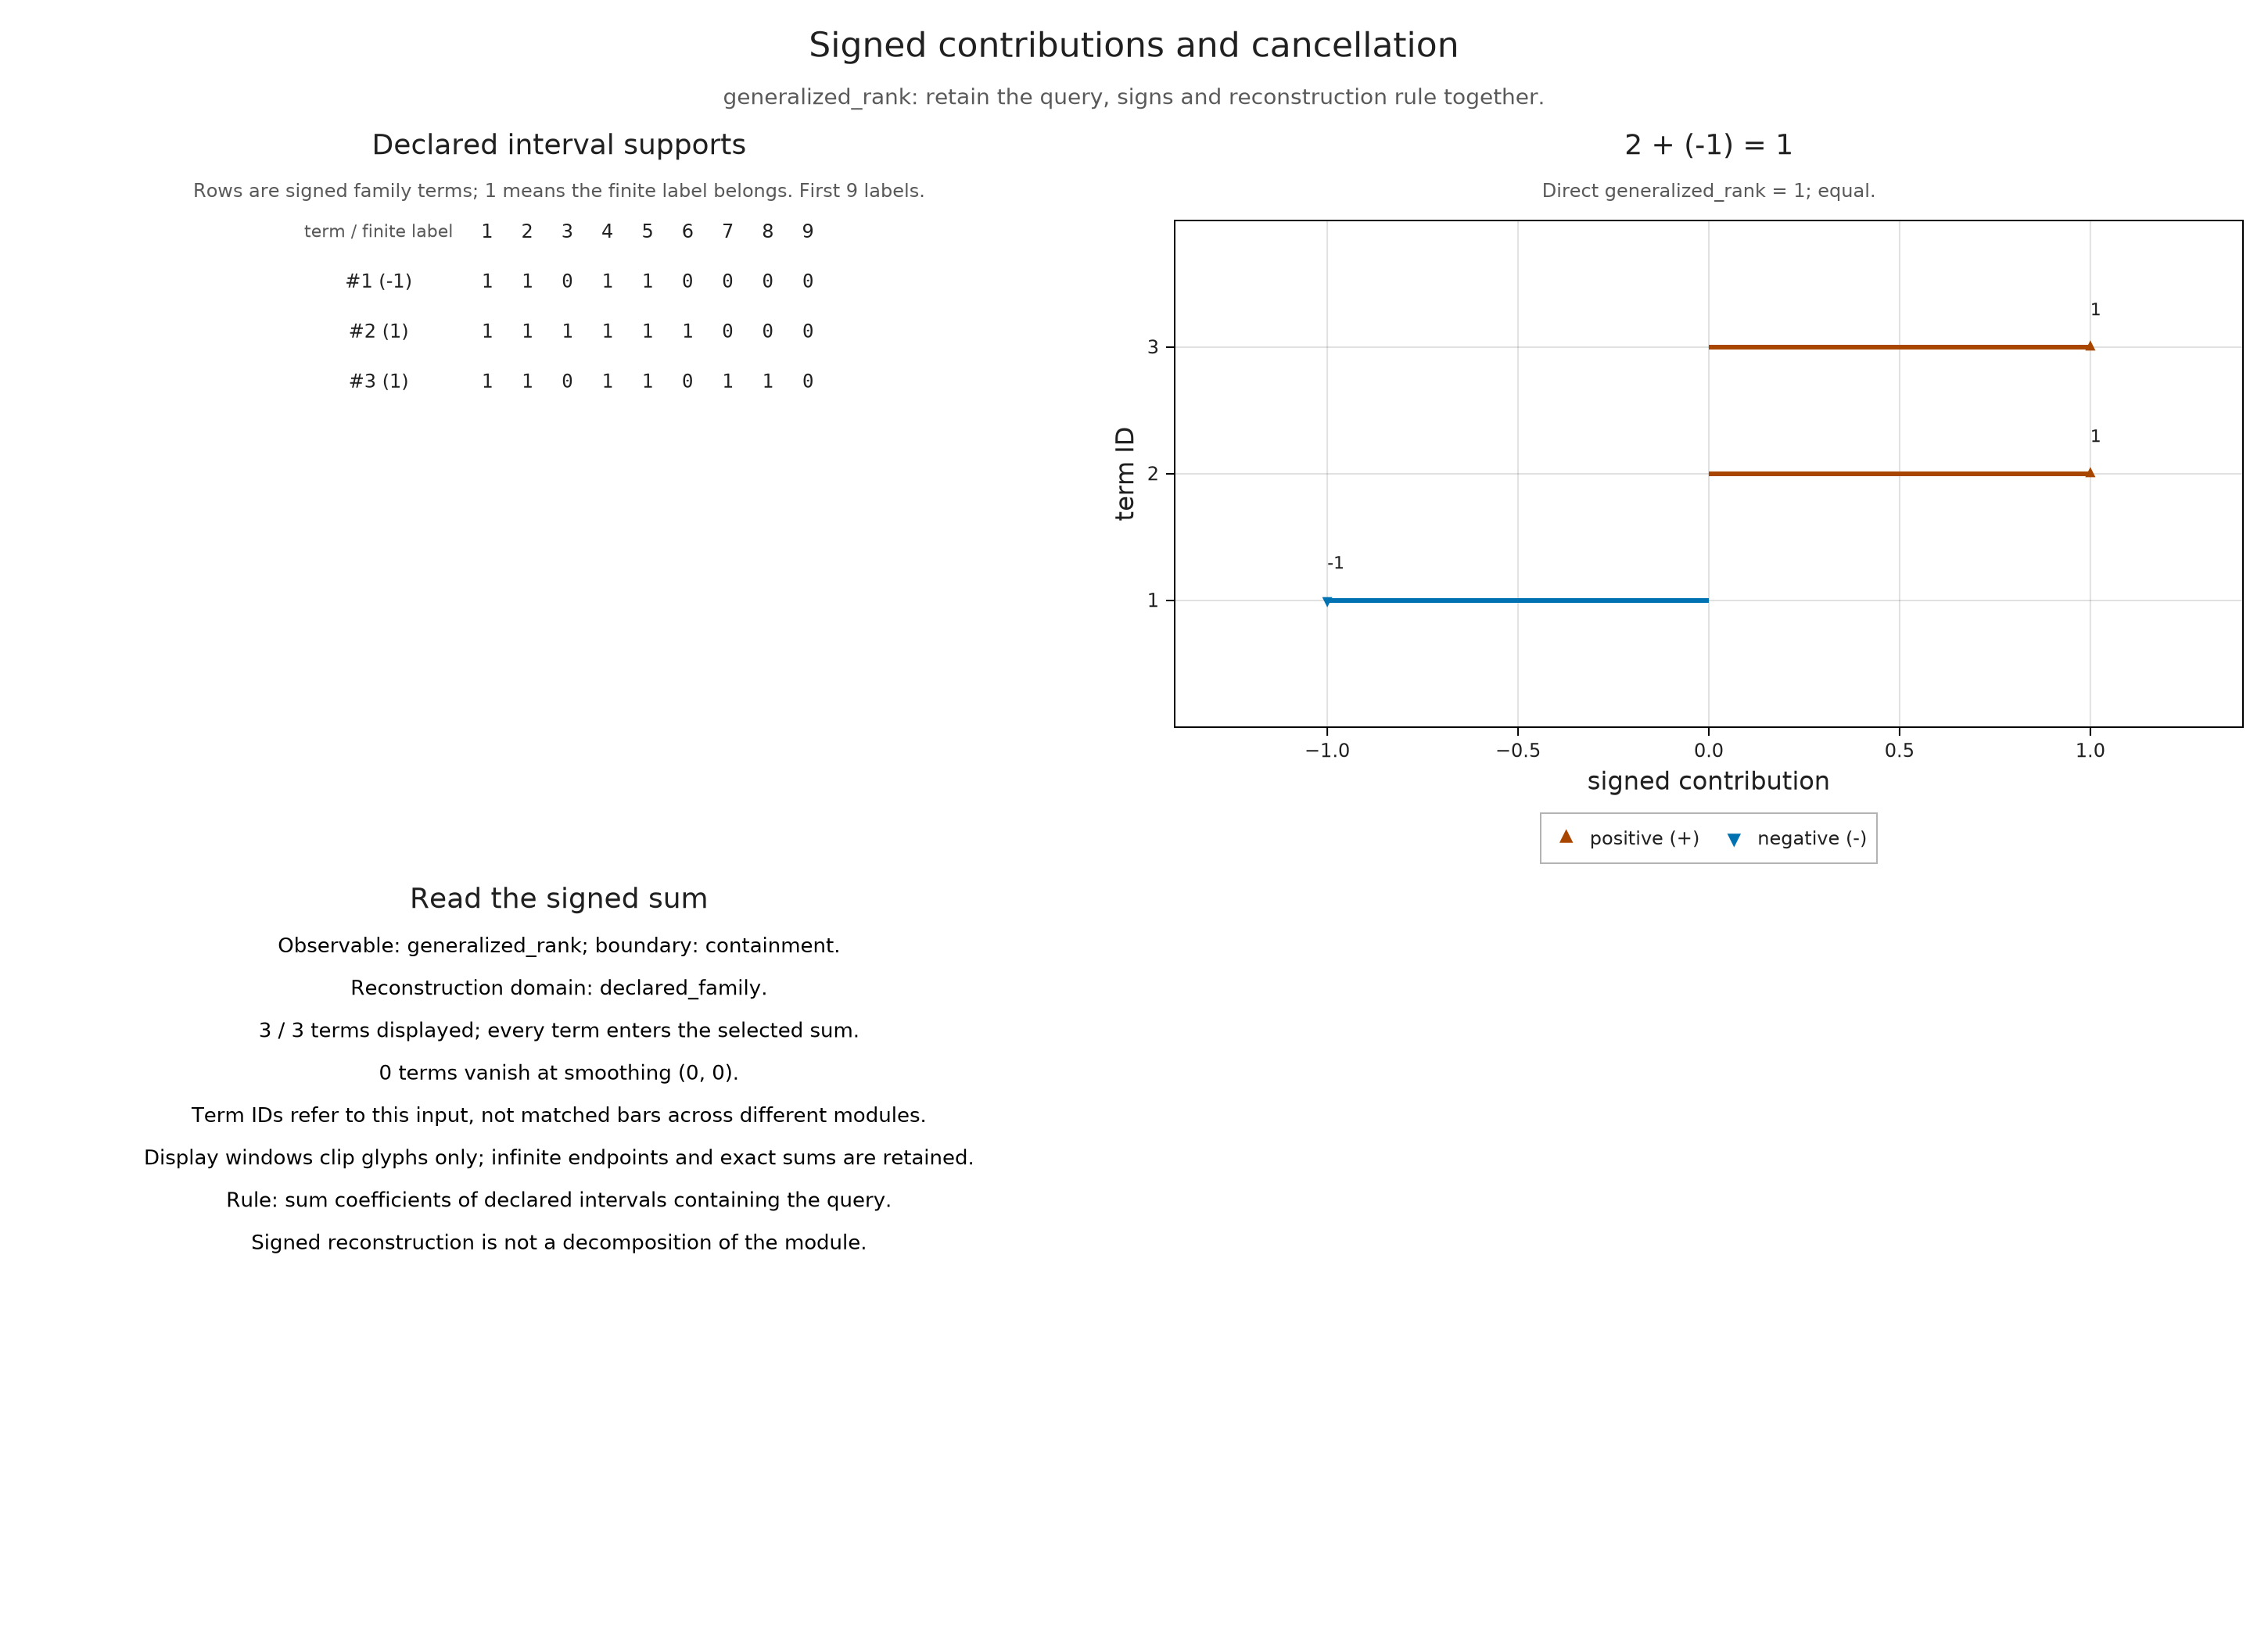

In [9]:
overlap = [1,2,4,5]
horizontal = [1,2,3,4,5,6]
vertical = [1,2,4,5,7,8]
family_summary = interval_rank_summary(encoding; family=[overlap,horizontal,vertical])
visualize(family_summary; query=(vertices=overlap,),
    direct=vertices -> generalized_rank(encoding; vertices))


Try moving the point query to (2,5). Predict the Hilbert value before changing
the call: only the positive birth atom contributes, so the answer is 1. For the
pair-rank query, try (0,0) to (5,5); its rank is zero. A negative coefficient is a
correction to one specified observable, not a negative-dimensional submodule.

## Optional: moving a slice

We can also move a line through the encoded module and inspect its restriction:

```julia
using WGLMakie
slices = inspection_session(encoding; box=([0,0],[6,6]),
    slice=(basepoint=(0,0), direction=(1,1)))
visualize(slices; backend=:wglmakie)
```

The two square handles lie on the chosen line. Moving the first translates it;
moving the second changes its direction. The angle and offset sliders provide
the same exploration with arrow keys. The displayed equation records the actual
basepoint and direction, so it also tells us how interval endpoints are measured
in the line parameter. Translating a line need not preserve those numbers even
when an interval continues to describe a related part of the support.

The barcode and diagram change together after a query completes. During a drag,
a pending message distinguishes the requested line from the one whose intervals
are still visible. Turn off **Continuous slice updates** to choose a slider
position before computing, or enter exact fractions and press **Apply slice**.
The closed viewing window specifies the restriction; an endpoint cut off by that
window does not establish that a class persists forever. Selecting a bar links
its interval within the current slice, without asserting a correspondence with
an interval on a different line.

When finished, `A.close_inspection!(slices)` releases the live session. Its final
`A.inspection_snapshot(slices)` remains available for a static figure.

## Optional: live selection and sharing

With WGLMakie loaded in a Julia session, the following opens linked controls.
Changing a term or view reuses the direct answer. Changing the query or smoothing
requests one fresh direct comparison. Invalid edits keep the previous snapshot.
The widget needs live Julia; an exported snapshot is static.

```julia
using WGLMakie
session = inspection_session(rank_measure;
    query=(p=(0,0), q=(2,2)), direct=direct_rank)
visualize(session)
# A.select_inspection!(session; term=negative_term)
# A.inspection_snapshot(session)
# A.close_inspection!(session)
```

For a static file, `save_visual("signed-rank.svg", signed_view; backend=:cairomakie)`
exports the same prepared mathematical answer. `max_terms` limits drawn terms;
the reconstruction always sums all retained coefficients.

For two slice diagrams, continue with the
[matching-witness recipe](distance_witness.ipynb). For exact keyword, boundary and
cost contracts, consult the [visualization reference](../src/reference/visualization.md#signed-observables-and-cancellation).
The [implementation account](../implementation/visual_specs.md#prepare-signed-contributions-before-drawing)
explains the retained metadata and reuse. None of these summaries reconstructs
the entire module in general; return to its spaces and maps when that information
is needed.
